# Day 5 lab: Applied Lab 5 — Predictive linear regression modelling

<p class="lead">
Predict a car's fuel efficiency from its engineering specifications the way a data scientist would: separate features from the target, train a multiple linear regression on 80% of the cars, predict the 20% it never saw, measure the error with RMSE, MAE and R², and check the model's health with a residual plot.
</p>

*Adapted from the DATA 300 syllabus, Applied Lab 5 (Predictive linear regression modeling), for local Jupyter without internet access.*

| | |
|---|---|
| **Graded** | Yes: **2%** of the course grade |
| **Outcomes** | CLO 4 and 5 |
| **Tool** | JupyterLab (Anaconda), with scikit-learn |
| **You submit** | One PDF, `YourLastName_DATA300_AppliedLab5.pdf`, in the **Applied Lab 5** drop-box on **GAP (Moodle)** |
| **Deadline** | Tuesday 17 November, 23:59 China Standard Time, unless your facilitator says otherwise (see the [schedule](schedule.md)) |

---

## The business scenario

You are a data scientist at an **automotive analytics consultancy**. A car manufacturer is designing its next models and must meet stricter fuel-efficiency rules. It asks you for a model that predicts a vehicle's fuel efficiency in **miles per gallon (MPG)** from its engineering specifications alone:

| Feature | Meaning | Unit |
|---|---|---|
| `cylinders` | Number of engine cylinders | count |
| `displacement` | Engine size | cubic inches |
| `horsepower` | Engine power | horsepower |
| `weight` | Vehicle weight | pounds |
| `acceleration` | Time from 0 to 60 mph | seconds |

The manufacturer will only trust the model if you **prove** that it works on vehicles it has never seen. So you hold back a fifth of the cars, train on the rest, and test on the hidden ones.

### Before you start

1. Keep this notebook in the course folder, next to the `data` folder.
2. Save your own copy: **File → Save Notebook As…** and type `YourLastName_Data300_AppliedLab5.ipynb` (with your real last name). Work in that copy.
3. The code below works as given. Run each cell in order with **Shift + Enter**, read the output, and answer the questions in Part 5. You may add cells of your own to check an answer.

---

## Part 1: Load the data and choose features and target

In predictive analytics the inputs are the **features** (X) and the value to predict is the **target** (y). A few cars have no horsepower recorded; linear regression cannot use a row with a missing value, so we drop those rows and say so.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Load the bundled mpg data (no internet needed)
df = pd.read_csv("data/mpg.csv")
print(f"Vehicles in the file: {len(df)}")
print("Missing values per column:", df.isna().sum()[df.isna().sum() > 0].to_dict())

# 2. Data cleaning: drop rows with missing values
df = df.dropna()

# 3. Features (X) and target (y)
features = ["cylinders", "displacement", "horsepower", "weight", "acceleration"]
X = df[features]
y = df["mpg"]

print("\n--- Dataset snapshot ---")
print(df[features + ["mpg"]].head().to_string())
print(f"\nTotal usable vehicles: {len(df)}")

Vehicles in the file: 398
Missing values per column: {'horsepower': 6}

--- Dataset snapshot ---
   cylinders  displacement  horsepower  weight  acceleration   mpg
0          8         307.0       130.0    3504          12.0  18.0
1          8         350.0       165.0    3693          11.5  15.0
2          8         318.0       150.0    3436          11.0  18.0
3          8         304.0       150.0    3433          12.0  16.0
4          8         302.0       140.0    3449          10.5  17.0

Total usable vehicles: 392


---

## Part 2: Train/test split and model training

To show that the model **predicts** rather than memorises, we split the cars at random: the model learns from 80% (the **training** set) and is then asked about the other 20% (the **test** set), which it never sees while it learns. `random_state=42` fixes the random split so everyone gets the same cars in each set.

Each **coefficient** is the expected change in MPG for one more unit of that feature, **holding the other four features fixed**.

In [2]:
# 1. Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training on {len(X_train)} vehicles...")
print(f"Testing on {len(X_test)} vehicles (hidden during training)...\n")

# 2. Fit the multiple linear regression on the training set only
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Coefficients: the business impact of each specification
print("--- Model coefficients (change in MPG per one-unit increase) ---")
coefficients = pd.DataFrame({"Feature": features, "Coefficient": model.coef_})
print(coefficients.to_string(index=False))
print(f"\nIntercept: {model.intercept_:.4f}")

Training on 313 vehicles...
Testing on 79 vehicles (hidden during training)...

--- Model coefficients (change in MPG per one-unit increase) ---
     Feature  Coefficient
   cylinders    -0.175808
displacement    -0.006713
  horsepower    -0.048908
      weight    -0.004992
acceleration    -0.060449

Intercept: 46.8371


Use this table for question 1.

---

## Part 3: Out-of-sample prediction and evaluation

The model now predicts the MPG of the hidden test cars from their specifications, and we compare its predictions with their real MPG:

| Measure | Meaning |
|---|---|
| **RMSE**, root mean squared error | A typical miss, in MPG; large misses count extra |
| **MAE**, mean absolute error | The average size of the miss, in MPG |
| **R²** on the test set | The share of the variation in the test cars' MPG that the model explains |

In the chart, each dot is one test car. The **dashed line** marks perfect predictions (predicted = actual): the closer the dots, the better.

--- Predictive performance on the TEST data ---
Root mean squared error (RMSE): 4.24 MPG
Mean absolute error (MAE): 3.49 MPG
Test R-squared (R2): 0.6485


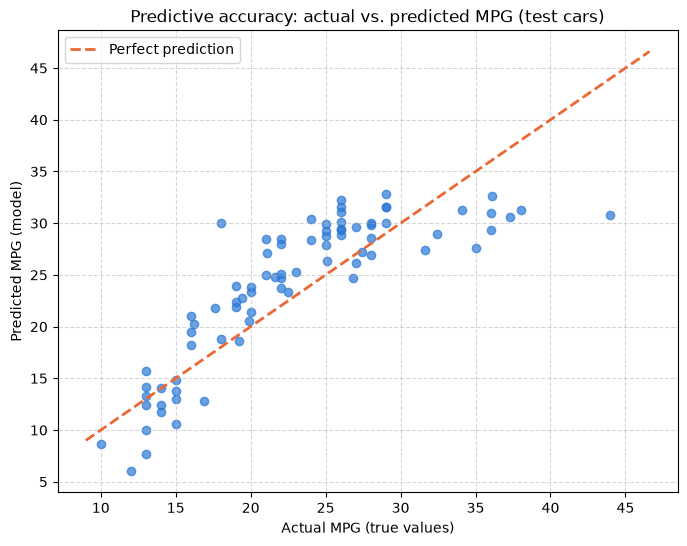

In [3]:
# 1. Predict the hidden TEST cars
y_pred = model.predict(X_test)

# 2. Evaluation measures
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2_test = r2_score(y_test, y_pred)

print("--- Predictive performance on the TEST data ---")
print(f"Root mean squared error (RMSE): {rmse:.2f} MPG")
print(f"Mean absolute error (MAE): {mae:.2f} MPG")
print(f"Test R-squared (R2): {r2_test:.4f}")

# 3. Actual vs predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color="#2a78d6")
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="#eb6834", linestyle="--", linewidth=2,
         label="Perfect prediction")
plt.title("Predictive accuracy: actual vs. predicted MPG (test cars)")
plt.xlabel("Actual MPG (true values)")
plt.ylabel("Predicted MPG (model)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Use these outputs for questions 2, 3 and 4.

---

## Part 4: Residual diagnostics

A **residual** is actual minus predicted MPG. A healthy linear model leaves residuals that look like a **random cloud** around zero, equally wide everywhere (**homoscedasticity**). A **pattern** (a U-shape, an arch, or a funnel that widens: **heteroscedasticity**) means the model is systematically wrong for some cars, often because the real relationship is curved.

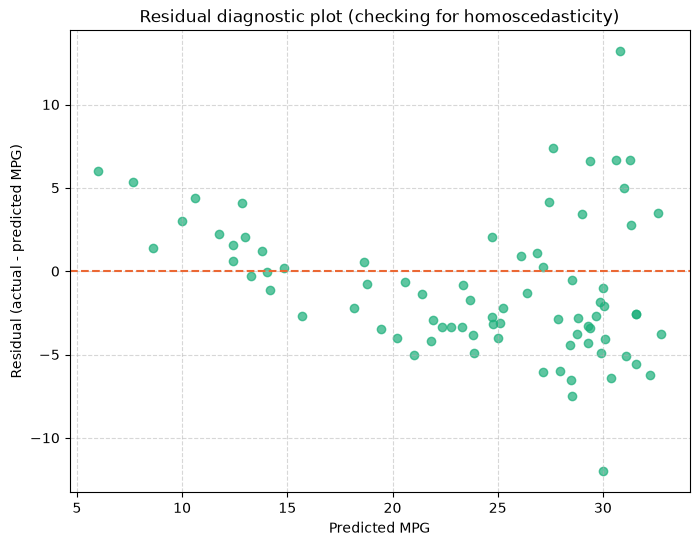

In [4]:
# Residuals: actual minus predicted
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color="#1baf7a")
plt.axhline(y=0, color="#eb6834", linestyle="--")
plt.title("Residual diagnostic plot (checking for homoscedasticity)")
plt.xlabel("Predicted MPG")
plt.ylabel("Residual (actual - predicted MPG)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Use this chart for question 5.

---

## Part 5: Questions

Answer **all five questions in complete sentences** in the answer cell below. Base every answer on the outputs in this notebook, and quote the numbers you use.

| # | Question |
|---|---|
| **1** | **Coefficients and design.** In the Part 2 table, the `weight` coefficient is about −0.005. Explain in plain words what it means for vehicle design: what happens to predicted MPG for each extra pound, and for an extra **1,000 pounds**, with the other specifications held fixed? |
| **2** | **Predictive performance.** State the test R² from Part 3. Because it was measured on cars the model never saw during training, what does it tell the manufacturer about how well the model will predict new vehicles? |
| **3** | **Error for engineers.** State the MAE from Part 3 and explain it in one sentence an engineer would understand, for example: "When the model predicts a car's MPG, it is usually off by about … MPG." |
| **4** | **Actual vs predicted.** In the Part 3 chart, are the dots tightly grouped around the dashed line or widely scattered? Does the model struggle more with low-MPG cars (around 15 MPG) or high-MPG cars (35 MPG or more)? |
| **5** | **Residuals.** In the Part 4 chart, do you see a random cloud around zero, or a U-shape or widening pattern? If there is a pattern, what does it suggest the straight-line model is missing? |

> **Writing tips**
>
> Lead with the answer, then the evidence: *"The test R² of … means …"*. Keep the units (MPG, pounds). Say "is associated with", not "causes": the coefficients come from past cars, not from an experiment.

> **My answers**
>
> **Name:** *Your name* · **Student ID:** *Your ID*
>
> **1. The weight coefficient, per pound and per 1,000 pounds:** *Your answer*
>
> **2. Test R² and what it says about new vehicles:** *Your answer*
>
> **3. MAE, explained for engineers:** *Your answer*
>
> **4. Grouping around the line; low- or high-MPG cars:** *Your answer*
>
> **5. Residual pattern and what it suggests:** *Your answer*

---

## Going further (not graded)

Two ideas a careful analyst would try next. First, the data include each car's **model year** and **origin** (USA, Europe, Japan); newer cars and imported cars were more efficient in this period. Second, the residual pattern suggests a **curve**: MPG falls steeply as weight rises from light cars, then more slowly. Predicting **1 / MPG** (gallons per mile, which grows roughly in proportion to weight) is a classic way to straighten it. The cell below compares the models on the **same** test cars, always reporting the error in MPG.

In [5]:
def test_scores(X_all, target="mpg"):
    """Fit on the same training cars, report R², RMSE and MAE in MPG on the same test cars."""
    Xtr, Xte = X_all.loc[X_train.index], X_all.loc[X_test.index]
    if target == "mpg":
        pred = LinearRegression().fit(Xtr, y_train).predict(Xte)
    else:   # model gallons per mile, then convert the prediction back to MPG
        pred = 1 / LinearRegression().fit(Xtr, 1 / y_train).predict(Xte)
    return {"test R²": r2_score(y_test, pred), "RMSE (MPG)": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE (MPG)": mean_absolute_error(y_test, pred)}


extra = pd.get_dummies(df[features + ["model_year", "origin"]], columns=["origin"], drop_first=True, dtype=float)
comparison = pd.DataFrame({
    "Lab model (5 specifications)": test_scores(df[features]),
    "+ model year and origin": test_scores(extra),
    "+ model year and origin, predicting 1/MPG": test_scores(extra, target="inverse"),
}).T
print(comparison.round(3).to_string())

                                           test R²  RMSE (MPG)  MAE (MPG)
Lab model (5 specifications)                 0.649       4.235      3.486
+ model year and origin                      0.792       3.256      2.462
+ model year and origin, predicting 1/MPG    0.850       2.766      2.110


Which change helps more: the extra features, or the change of target? Plot the residuals of the best model the same way as in Part 4: has the pattern gone? Remember that adding `model_year` changes the meaning of the question: the manufacturer asked about **engineering specifications** only, and a future car's model year is not a design choice.

---

## Part 6: Export and submit

### 1. Export to PDF

1. Choose **Kernel → Restart Kernel and Run All Cells**. Check that the data snapshot, the coefficients, the three error measures and both charts appear, and that your answers are in the answer cell.
2. Choose **File → Print** (or Ctrl + P / Cmd + P).
3. Set the destination to **Save as PDF**. Under *More settings*, tick **Background graphics** so the colours are kept.
4. Save the file as **`YourLastName_DATA300_AppliedLab5.pdf`**, with your real last name.

Your answers are inside the notebook, so this one PDF is the whole submission. If your facilitator asks you to answer in a Word document instead, combine the two PDFs into one file without internet, as shown in [Combining PDFs without internet](setup.md#combining-pdfs-without-internet).

### 2. Upload

Log in to **GAP (Moodle)**, open the **DATA 300: Applied Lab 5** drop-box, upload the PDF and click **Submit** by **23:59 China Standard Time today**.

---

## Checklist before you upload

- [ ] The notebook was **restarted and run all**; the coefficients, RMSE, MAE and test R² all appear.
- [ ] Both charts appear, in colour.
- [ ] All five questions are answered in complete sentences, with the numbers you used.
- [ ] Your name and student ID are in the answer cell.
- [ ] The file is named `YourLastName_DATA300_AppliedLab5.pdf` and uploaded to the Applied Lab 5 drop-box on GAP (Moodle).

## How it is marked

The lab uses the course's Lab 5 rubric: **CLO 4** (developing predictive models such as linear regression to project outcomes, 40 points), **CLO 5** (evaluating how an analytical model supports managerial decisions, 40 points), **professional formatting** (10 points) and **clear academic writing** (10 points). In practice: all outputs present, correct values quoted, coefficients and errors explained in business terms, a reasoned reading of both charts, and a correctly named PDF.

> **Stuck?**
>
> `FileNotFoundError: data/mpg.csv`: your notebook is not in the course folder next to `data`; move it there. `ModuleNotFoundError` for `sklearn`: run the [setup check](00_setup_check.md) and follow its fix. For anything else, take a screenshot and ask your facilitator.